# 06 — csPCa Classification with XGBoost

## Objective

This notebook implements the classification stage of the pipeline using
whole-gland radiomic features extracted from T2W MRI.

The workflow includes:

1. Loading the radiomic feature dataset
2. Adding the csPCa target and patient-level data split
3. Validating the classification dataset
4. Preparing training, validation, and test sets
5. Training the XGBoost classifier
6. Evaluating classification performance

The binary target is `case_csPCa`, where positive cases represent
clinically significant prostate cancer.

## 1. Imports and paths

In [10]:
from pathlib import Path
import json
import time
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (accuracy_score, average_precision_score,
                             balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score,
                             PrecisionRecallDisplay, recall_score,
                             roc_auc_score, RocCurveDisplay, roc_curve)
from xgboost import XGBClassifier

RANDOM_STATE = 42
EXPECTED_FEATURES = 107
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd
features_path = PROJECT_ROOT / "src/data/features/whole_gland_t2w_radiomics.csv"
clinical_path = PROJECT_ROOT / "src/data/raw/picai_labels/clinical_information/marksheet.csv"
splits_path = PROJECT_ROOT / "src/data/processed/splits/patient_splits.csv"
# Keep reconstruction results separate from current validated grouped-v2 work.
results_dir = PROJECT_ROOT / "results/classification_original_reconstruction"
for name, path in [("Features", features_path), ("Clinical", clinical_path), ("Splits", splits_path)]:
    print(f"{name}: {path} | exists={path.is_file()}")


Features: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\features\whole_gland_t2w_radiomics.csv | exists=True
Clinical: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\raw\picai_labels\clinical_information\marksheet.csv | exists=True
Splits: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\processed\splits\patient_splits.csv | exists=True


## 2. Load radiomics, clinical target, and predefined splits

In [11]:
id_columns = ["patient_id", "study_id"]
features_df = pd.read_csv(features_path, dtype={c: str for c in id_columns})
clinical_df = pd.read_csv(clinical_path, dtype={c: str for c in id_columns})
splits_df = pd.read_csv(splits_path, dtype={c: str for c in id_columns})

feature_columns = [column for column in features_df.columns if column.startswith("original_")]
assert len(feature_columns) == EXPECTED_FEATURES, f"Expected 107 radiomic features, got {len(feature_columns)}"
for name, frame in [("radiomics", features_df), ("clinical", clinical_df), ("splits", splits_df)]:
    assert not frame.duplicated(id_columns).any(), f"Duplicate examination keys in {name}"

classification_df = (features_df
    .merge(clinical_df[id_columns + ["case_csPCa"]], on=id_columns, how="inner", validate="one_to_one")
    .merge(splits_df[id_columns + ["split"]], on=id_columns, how="inner", validate="one_to_one"))
classification_df["target"] = classification_df["case_csPCa"].map({"NO": 0, "YES": 1})
assert classification_df["target"].notna().all(), "Unexpected target labels"
assert classification_df["split"].isin(["train", "validation", "test"]).all()
classification_df["target"] = classification_df["target"].astype(int)
print("Examinations:", len(classification_df))
print("Unique patients:", classification_df.patient_id.nunique())
display(pd.crosstab(classification_df["split"], classification_df["target"]))


Examinations: 1500
Unique patients: 1476


C:\Users\Luiz Trindade\AppData\Local\Temp\ipykernel_15528\3622257855.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  classification_df["target"] = classification_df["case_csPCa"].map({"NO": 0, "YES": 1})


target,0,1
split,,
test,162,63
train,752,298
validation,161,64


## 3. Validate the classification dataset

The original split is inspected, **not** assumed to be patient-disjoint. If any patients appear in multiple splits, stop for reproducible scientific evaluation and use `patient_splits_grouped_v2.csv` instead.

In [12]:
patient_split_counts = classification_df.groupby("patient_id")["split"].nunique()
n_overlapping = int((patient_split_counts > 1).sum())
print("Patients in multiple partitions:", n_overlapping)
print("Missing radiomic entries:", int(classification_df[feature_columns].isna().sum().sum()))
print("Infinite radiomic entries:", int(np.isinf(classification_df[feature_columns].to_numpy(dtype=float)).sum()))
if n_overlapping:
    print("WARNING: historical split has patient leakage. Do not report outputs as valid final test results.")


Patients in multiple partitions: 10
Missing radiomic entries: 0
Infinite radiomic entries: 0


## 4. Prepare training, validation, and test sets

In [13]:
split_frames = {split: classification_df.loc[classification_df["split"] == split].copy()
                for split in ["train", "validation", "test"]}
X = {split: frame[feature_columns].copy() for split, frame in split_frames.items()}
y = {split: frame["target"].copy() for split, frame in split_frames.items()}
for split in ["train", "validation", "test"]:
    assert np.isfinite(X[split].to_numpy(dtype=float)).all(), f"Nonfinite radiomics in {split}"
    print(split, X[split].shape, y[split].value_counts().to_dict())


train (1050, 107) {0: 752, 1: 298}
validation (225, 107) {0: 161, 1: 64}
test (225, 107) {0: 162, 1: 63}


## 5. Train XGBoost classifier

The parameters below reflect the historical configuration preserved in the discussion (150 trees, depth 3, learning rate 0.03, and stronger regularization). This reconstruction does **not** reproduce the missing hyperparameter-search history.

In [14]:
negative_count = int((y["train"] == 0).sum())
positive_count = int((y["train"] == 1).sum())
scale_pos_weight = negative_count / positive_count

xgb_parameters = dict(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=10,
    reg_alpha=0.5,
    reg_lambda=10.0,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
start = time.perf_counter()
xgb_model = XGBClassifier(**xgb_parameters)
xgb_model.fit(X["train"], y["train"])
print(f"Training time: {time.perf_counter() - start:.2f} s")


Training time: 1.17 s


## 6. Evaluate on validation and select the threshold

The historical record mentions a selected threshold of approximately `0.4787`. It may not reproduce exactly without the original execution and hyperparameter-selection history. The cell below **recomputes** a validation-only Youden threshold rather than hardcoding a historical value.

In [15]:
validation_scores = xgb_model.predict_proba(X["validation"])[:, 1]
print("Validation ROC-AUC:", round(roc_auc_score(y["validation"], validation_scores), 4))
print("Validation AP:", round(average_precision_score(y["validation"], validation_scores), 4))
fpr, tpr, thresholds = roc_curve(y["validation"], validation_scores)
finite = np.isfinite(thresholds)
youden = tpr[finite] - fpr[finite]
selected_threshold = float(thresholds[finite][np.argmax(youden)])
print("Validation-selected Youden threshold:", selected_threshold)


Validation ROC-AUC: 0.7125
Validation AP: 0.4589
Validation-selected Youden threshold: 0.4786553978919983


## 7. Test-set evaluation

**Historical-reproduction only.** If the original splits overlap by patient, this test evaluation is contaminated and must not be used in the TCC conclusions. No threshold or parameter changes should be made in response to test metrics.

In [16]:
test_scores = xgb_model.predict_proba(X["test"])[:, 1]
test_predictions = (test_scores >= selected_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y["test"], test_predictions, labels=[0, 1]).ravel()
test_metrics = {
    "threshold": selected_threshold,
    "roc_auc": roc_auc_score(y["test"], test_scores),
    "average_precision": average_precision_score(y["test"], test_scores),
    "accuracy": accuracy_score(y["test"], test_predictions),
    "balanced_accuracy": balanced_accuracy_score(y["test"], test_predictions),
    "sensitivity": recall_score(y["test"], test_predictions),
    "specificity": tn / (tn + fp),
    "precision": precision_score(y["test"], test_predictions, zero_division=0),
    "f1_score": f1_score(y["test"], test_predictions, zero_division=0),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
}
display(pd.DataFrame([test_metrics]).round(4))


,threshold,roc_auc,average_precision,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1_score,tn,fp,fn,tp
0,0.4787,0.6639,0.4496,0.6222,0.6213,0.619,0.6235,0.39,0.4785,101,61,24,39


## 8. Classification plots

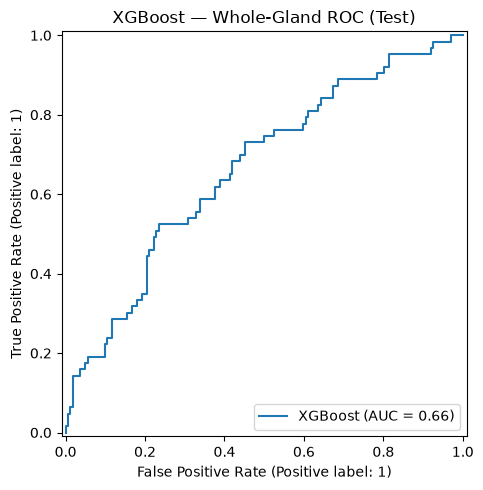

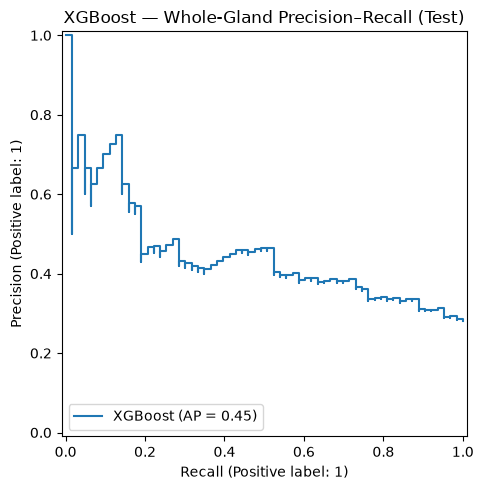

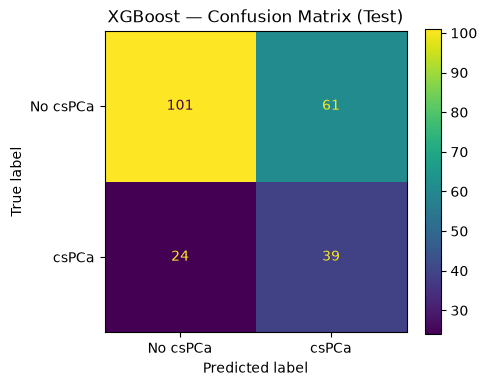

In [17]:
results_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y["test"], test_scores, name="XGBoost", ax=ax)
ax.set_title("XGBoost — Whole-Gland ROC (Test)")
fig.tight_layout()
fig.savefig(results_dir / "test_roc_curve.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y["test"], test_scores, name="XGBoost", ax=ax)
ax.set_title("XGBoost — Whole-Gland Precision–Recall (Test)")
fig.tight_layout()
fig.savefig(results_dir / "test_pr_curve.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y["test"], test_predictions,
    labels=[0, 1], display_labels=["No csPCa", "csPCa"], ax=ax)
ax.set_title("XGBoost — Confusion Matrix (Test)")
fig.tight_layout()
fig.savefig(results_dir / "test_confusion_matrix.png", dpi=160)
plt.show()


## 9. Save model and results

These artifacts are labeled as reconstructed and saved separately from both the historical results and the grouped-v2 experiment.

In [18]:
joblib.dump(xgb_model, results_dir / "xgboost_reconstructed.joblib")
xgb_model.save_model(str(results_dir / "xgboost_reconstructed.json"))
pd.DataFrame([test_metrics]).to_csv(results_dir / "test_metrics_reconstructed.csv", index=False)
predictions_df = split_frames["test"][id_columns + ["target"]].copy()
predictions_df["score"] = test_scores
predictions_df["prediction"] = test_predictions
predictions_df.to_csv(results_dir / "test_predictions_reconstructed.csv", index=False)
metadata = {
    "provenance": "reconstruction; not an original historical notebook",
    "notebook_title": "06 — csPCa Classification with XGBoost",
    "input_features": str(features_path),
    "input_splits": str(splits_path),
    "n_features": len(feature_columns),
    "feature_names": feature_columns,
    "model_parameters": xgb_parameters,
    "selected_threshold": selected_threshold,
    "patient_overlap_between_splits": n_overlapping,
}
with open(results_dir / "metadata_reconstructed.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, default=str)
print("Reconstructed artifacts saved to:", results_dir)


Reconstructed artifacts saved to: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\results\classification_original_reconstruction
